# DES Y6 data products: review

A read-only look at every product of `msfm.apps.products.desy6` (`data/desy6/README.md`).
It writes nothing. The checks that gate a product run inside the steps; this notebook is for looking, and for the two
questions the steps cannot settle on their own:

- the coverage threshold of the footprint;
- the shear convention: κ_E × δ_g must be positive and κ_B × δ_g null, the decisive test for Y3.

Run it after the steps `nz`, `pixels`, `maps`, `values`, `config` and `noise`, in `torch_env` (healpy, h5py,
matplotlib, msfm from this checkout).

In [1]:
from pathlib import Path

import h5py
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import yaml

import msfm
from msfm.apps.products import desy6
from msfm.utils import catalog_desy6, files, filenames, lensing

REPO = Path(msfm.__file__).resolve().parents[1]
CONFIG = REPO / "configs/desy6/v1/default.yaml"
conf = files.load_config(str(CONFIG))

n_side = conf["analysis"]["n_side"]
n_pix = hp.nside2npix(n_side)
pix_area = hp.nside2pixarea(n_side, degrees=True)

# every product holds all survey bins; the config's z_bins select from them
survey_labels = {"metacal": [f"metacal{i}" for i in range(1, 5)], "maglim": [f"maglim{i}" for i in range(1, 7)]}
used = {sample: conf["survey"][sample]["z_bins"] for sample in survey_labels}
print(used)

{'metacal': ['metacal1', 'metacal2', 'metacal3', 'metacal4'], 'maglim': ['maglim1', 'maglim3', 'maglim4', 'maglim5', 'maglim6']}


## Provenance

The steps run with `--provenance`: on which commit, and whether every recorded output is still the file on disk.

In [2]:
with open(REPO / conf["files"]["provenance"]) as f:
    prov = yaml.safe_load(f)["steps"]

for step, record in prov.items():
    print(f"{step:8s} {record['date']}  msfm {record['msfm_commit'][:10]}")
    for out in record["outputs"]:
        path = REPO / out["path"]
        state = "missing" if not path.exists() else ("ok" if desy6._sha256(path) == out["sha256"] else "CHANGED")
        print(f"    {state:8s} {out['path']}")

# a step run without --provenance leaves no record
print("no record:", [step for step in desy6.STEP_ORDER if step not in prov])

nz       2026-11-18T13:43:42+01:00  msfm 73f58dcd0a
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin1.txt
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin2.txt
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin3.txt
    ok       data/desy6/redshift_distributions/desy6_nz_metacal_bin4.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin1.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin2.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin3.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin4.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin5.txt
    ok       data/desy6/redshift_distributions/desy6_nz_maglim_bin6.txt
no record: ['pixels', 'maps', 'values', 'config', 'noise', 'sc_bias']


## n(z)

The fiducial n(z) of the 3x2pt FITS. Dotted lines are survey bins the config does not use. The grid starts at
z = 0.00, unlike Y3's 0.005.

grid starts at z = 0.0; n(z) there: {'metacal1': np.float64(0.0), 'metacal2': np.float64(0.0), 'metacal3': np.float64(0.0), 'metacal4': np.float64(0.0), 'maglim1': np.float64(0.0), 'maglim2': np.float64(0.0), 'maglim3': np.float64(0.0), 'maglim4': np.float64(0.0), 'maglim5': np.float64(0.0), 'maglim6': np.float64(0.0)}


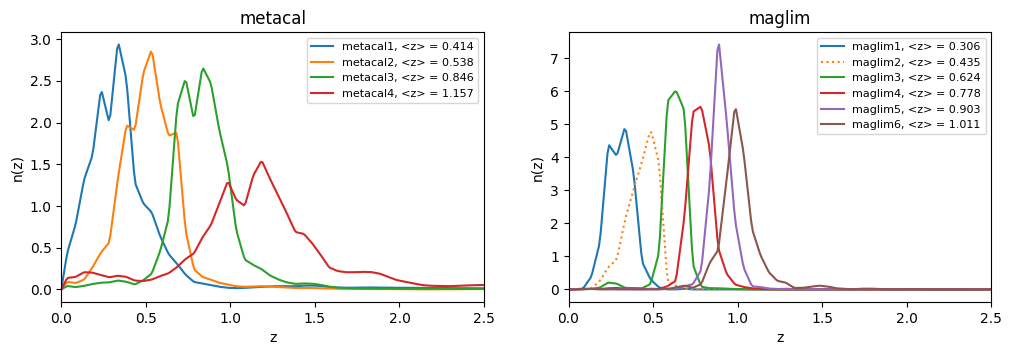

In [3]:
nz_dir = str(REPO / conf["dirs"]["redshift_distributions"])
mean_z, nz_at_grid_start = {}, {}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for ax, (sample, labels) in zip(axes, survey_labels.items()):
    for i_bin, label in enumerate(labels, start=1):
        z, nz = np.loadtxt(filenames.get_filename_z_distribution(nz_dir, sample, i_bin, prefix=desy6.FILE_PREFIX)).T
        mean_z[label], nz_at_grid_start[label] = np.sum(z * nz) / np.sum(nz), nz[0]
        style = "-" if label in used[sample] else ":"
        ax.plot(z, nz, style, label=f"{label}, <z> = {mean_z[label]:.3f}")
    ax.set(xlabel="z", ylabel="n(z)", title=sample, xlim=(0, 2.5))
    ax.legend(fontsize=8)

print(f"grid starts at z = {z[0]}; n(z) there: {nz_at_grid_start}")

## Footprint and the coverage threshold

The pixel file stores the rotated coverage of every nside-512 pixel (`footprint/coverage`), so the threshold can be
re-derived here without healsparse. As in Y3 (0.72), it is chosen so the footprint area matches the mask area.
Pixels below the threshold leave the footprint, at its edges and as interior holes (pixels below the threshold whose
eight neighbours are all in the footprint). About 11% of the mask area is lost this way (Y3: 8%), mostly through the
lower coverage of the Y6 pixels; the number of holes is similar to Y3's.

In [4]:
with h5py.File(REPO / conf["files"]["pixels"], "r") as f:
    attrs = dict(f.attrs)
    coverage = f["footprint/coverage"][:].astype(np.float64)
    patches = f["footprint/patches"][:]
    data_vec = f["data_vec"][:]
for key, value in attrs.items():
    print(f"{key}: {value}")

threshold = attrs["coverage_threshold"]
footprint = patches[0]
in_footprint = np.zeros(n_pix, dtype=bool)
in_footprint[footprint] = True
print(
    f"\nfootprint: {footprint.size} pixels, {footprint.size * pix_area:.1f} deg^2 (mask {attrs['area_deg2']:.3f}), "
    f"mean coverage {coverage[footprint].mean():.4f}; data vector {data_vec.size} pixels"
)
print(
    f"mask area in the footprint {coverage[footprint].sum() * pix_area:.1f} deg^2, "
    f"outside {coverage[~in_footprint].sum() * pix_area:.1f} deg^2, "
    f"fraction inside {coverage[footprint].sum() / coverage.sum():.4f}"
)

# holes: below the threshold, but surrounded by the footprint
neighbours = hp.get_all_neighbours(n_side, np.arange(n_pix))
surrounded = np.all(in_footprint[neighbours] | (neighbours < 0), axis=0)
holes = surrounded & ~in_footprint
print(f"{holes.sum()} holes; their coverage: {np.round(np.sort(coverage[holes]), 3)[:30]}")

area_deg2: 4031.03590997686
coverage_threshold: 0.73
info: DES Y6 jointmask_DESY6_2024-06-04.hsp, rotated by analysis.footprint.rotation, at nside 512. Written by msfm.apps.products.desy6 pixels
rotate_nside: 4096
rotation_y_rad: -0.125
rotation_z_rad: -1.22

footprint: 309226 pixels, 4055.2 deg^2 (mask 4031.036), mean coverage 0.8840; data vector 457728 pixels
mask area in the footprint 3584.6 deg^2, outside 446.4 deg^2, fraction inside 0.8893


5922 holes; their coverage: [0.014 0.027 0.048 0.054 0.054 0.067 0.069 0.07  0.114 0.121 0.132 0.133
 0.144 0.147 0.149 0.151 0.152 0.153 0.155 0.157 0.159 0.162 0.163 0.166
 0.168 0.172 0.174 0.176 0.18  0.181]


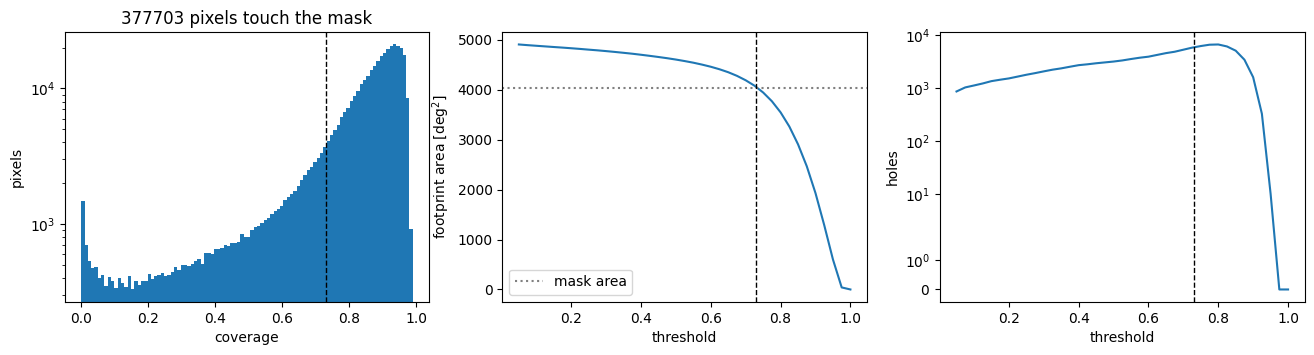

In [5]:
touched = coverage[coverage > 0]
thresholds = np.linspace(0.05, 1, 39)

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 3.5))
ax0.hist(touched, bins=100, log=True)
ax0.set(xlabel="coverage", ylabel="pixels", title=f"{touched.size} pixels touch the mask")

ax1.plot(thresholds, [np.sum(coverage >= t) * pix_area for t in thresholds])
ax1.axhline(attrs["area_deg2"], color="gray", ls=":", label="mask area")
ax1.set(xlabel="threshold", ylabel="footprint area [deg$^2$]")
ax1.legend()

n_holes = [np.sum(np.all((coverage >= t)[neighbours] | (neighbours < 0), axis=0) & (coverage < t)) for t in thresholds]
ax2.plot(thresholds, n_holes)
ax2.set(xlabel="threshold", ylabel="holes", yscale="symlog")

for ax in (ax0, ax1, ax2):
    ax.axvline(threshold, color="k", ls="--", lw=1)

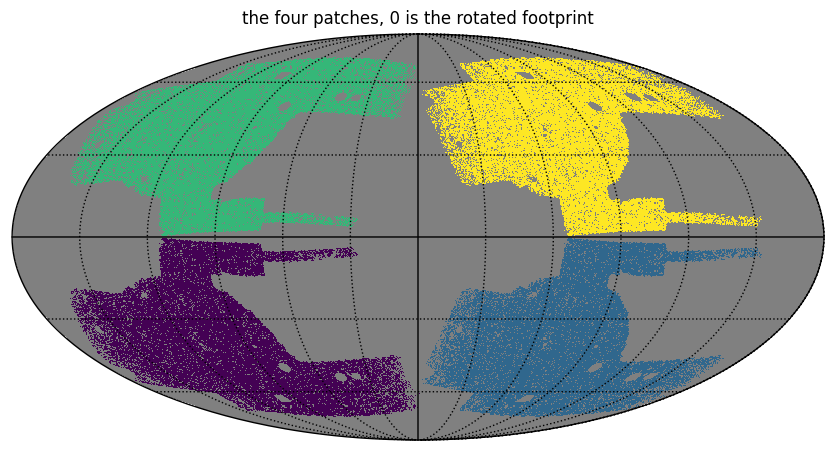

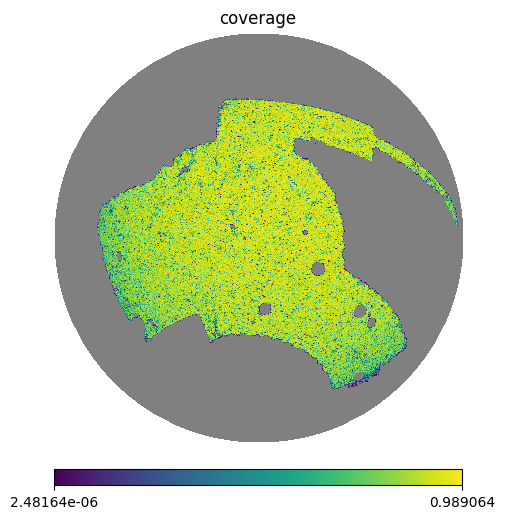

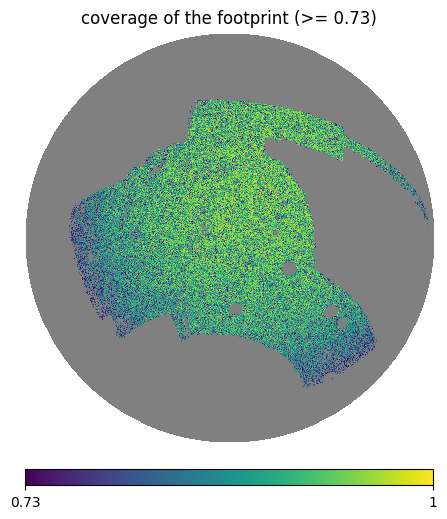

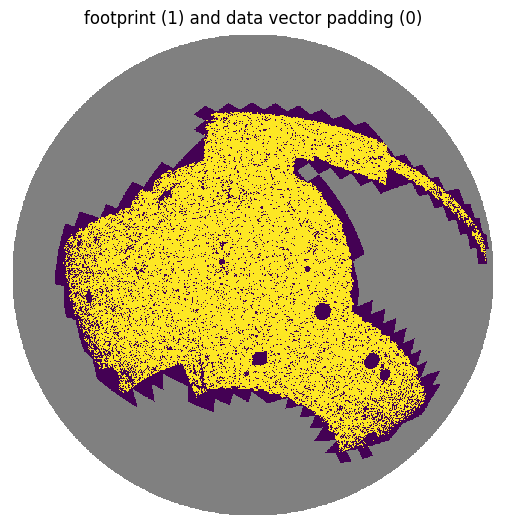

In [6]:
patch_map = np.full(n_pix, hp.UNSEEN)
for i, patch in enumerate(patches):
    patch_map[patch] = i
hp.mollview(patch_map, title="the four patches, 0 is the rotated footprint", cbar=False)
hp.graticule()

# centre of the rotated footprint, for the zooms below
lon, lat = hp.vec2ang(np.mean(hp.pix2vec(n_side, footprint), axis=1), lonlat=True)
centre = (float(np.ravel(lon)[0]), float(np.ravel(lat)[0]))

hp.orthview(np.where(coverage > 0, coverage, hp.UNSEEN), rot=centre, half_sky=True, title="coverage")
kept = np.full(n_pix, hp.UNSEEN)
kept[footprint] = coverage[footprint]
hp.orthview(kept, rot=centre, half_sky=True, title=f"coverage of the footprint (>= {threshold})", min=threshold, max=1)
padding = np.full(n_pix, hp.UNSEEN)
padding[hp.nest2ring(n_side, data_vec)] = 0
padding[footprint] = 1
hp.orthview(padding, rot=centre, half_sky=True, title="footprint (1) and data vector padding (0)", cbar=False)

## Survey values and the config

The values file next to DES's numbers (`3x2pt_pipeline_public.ipynb` for R and the area, the methods paper for m),
then the step `config --check`, which writes nothing.

In [7]:
with open(REPO / conf["files"]["survey_values"]) as f:
    values = yaml.safe_load(f)["survey"]
shear = values["metacal"]["shear_bias"]["multiplicative"]
response_des = catalog_desy6.SOURCE_DES["response"][0]

print(f"Aeff = {values['Aeff']:.4f} deg^2 (DES {catalog_desy6.AREA_DES})\n")
print(f"{'bin':9s} {'n_gal [arcmin^-2]':>18s} {'R':>9s} {'R (DES)':>9s} {'m mu':>9s} {'m (DES)':>8s} {'m sigma':>8s}")
for i, label in enumerate(survey_labels["metacal"]):
    print(
        f"{label:9s} {values['metacal']['n_gal'][label] / 60**2:18.4f} {values['metacal']['response'][label]:9.6f} "
        f"{response_des[i]:9.6f} {shear['mu'][label]:9.5f} {catalog_desy6.M_MEAN_DES[i]:8.5f} "
        f"{shear['sigma'][label]:8.5f}"
    )
for label in survey_labels["maglim"]:
    note = "" if label in used["maglim"] else "  (not used)"
    print(f"{label:9s} {values['maglim']['n_gal'][label] / 60**2:18.4f}{note}")

try:
    desy6.main(["config", "--config", str(CONFIG), "--check"])
except SystemExit as error:
    print(f"config --check: STALE (exit {error.code}), run the step config")

Aeff = 4031.0359 deg^2 (DES 4031.036)

bin        n_gal [arcmin^-2]         R   R (DES)      m mu  m (DES)  m sigma
metacal1              2.0650  0.856143  0.856143  -0.00340 -0.00340  0.00578
metacal2              2.1210  0.868506  0.868506   0.00646  0.00646  0.00662
metacal3              2.1327  0.819427  0.819427   0.01594  0.01594  0.00594
metacal4              2.2730  0.691769  0.691769   0.00170  0.00170  0.01220
maglim1               0.1129
maglim2               0.0814  (not used)
maglim3               0.0862
maglim4               0.1088
maglim5               0.0849
maglim6               0.0860
26-11-20 08:52:26     desy6.py INF   configs/desy6/v1/default.yaml: all 6 marked values agree with data/desy6/desy6_survey_values.yaml 


## Maps

The cached maps of the step `maps`, all survey bins. The mean shear is not subtracted, as in Y3; it is printed here
next to the per-pixel rms. For Y3 it was about 1.5% of the rms.

In [8]:
cache = REPO / conf["dirs"]["cache"]
gamma = np.load(cache / desy6.MAPS_FILES["metacal_gamma"])  # (n_pix, 4, 2)
source_count = np.load(cache / desy6.MAPS_FILES["metacal_count"])  # (n_pix, 4)
lens_count = np.load(cache / desy6.MAPS_FILES["maglim_count"])  # (n_pix, 6)
lens_weighted = np.load(cache / desy6.MAPS_FILES["maglim_weighted_count"])  # (n_pix, 6)

for i, label in enumerate(survey_labels["metacal"]):
    n = source_count[:, i]
    g = gamma[footprint, i]
    mean = np.average(g, weights=n[footprint], axis=0)
    rms = np.sqrt(np.average(g**2, weights=n[footprint], axis=0))
    print(
        f"{label}: {n[footprint].sum() / n.sum():.4f} of {n.sum()} galaxies in the footprint, "
        f"mean (g1, g2) = ({mean[0]:+.2e}, {mean[1]:+.2e}), rms ({rms[0]:.3f}, {rms[1]:.3f})"
    )
for j, label in enumerate(survey_labels["maglim"]):
    n, w = lens_count[:, j], lens_weighted[:, j]
    print(
        f"{label}: {n[footprint].sum() / n.sum():.4f} of {n.sum()} galaxies in the footprint, "
        f"mean weight there {w[footprint].sum() / n[footprint].sum():.4f}"
    )

metacal1: 0.8943 of 33707071 galaxies in the footprint, mean (g1, g2) = (+1.41e-04, -3.88e-05), rms (0.029, 0.029)
metacal2: 0.8954 of 34580888 galaxies in the footprint, mean (g1, g2) = (-7.84e-06, +6.67e-05), rms (0.031, 0.031)
metacal3: 0.8986 of 34646416 galaxies in the footprint, mean (g1, g2) = (+1.95e-04, +2.10e-04), rms (0.030, 0.030)
metacal4: 0.9035 of 36727798 galaxies in the footprint, mean (g1, g2) = (+2.87e-04, -7.56e-05), rms (0.036, 0.036)
maglim1: 0.8910 of 1852538 galaxies in the footprint, mean weight there 0.9984
maglim2: 0.8911 of 1335294 galaxies in the footprint, mean weight there 0.9987
maglim3: 0.8916 of 1413738 galaxies in the footprint, mean weight there 0.9984
maglim4: 0.8919 of 1783834 galaxies in the footprint, mean weight there 0.9981
maglim5: 0.8914 of 1391521 galaxies in the footprint, mean weight there 0.9992
maglim6: 0.8935 of 1409280 galaxies in the footprint, mean weight there 0.9972


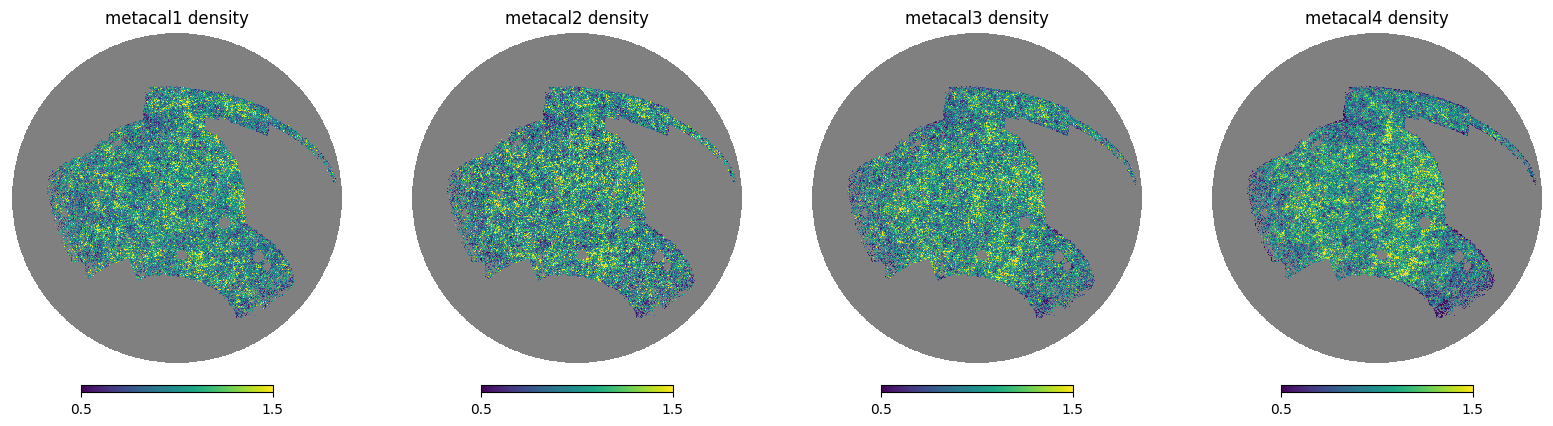

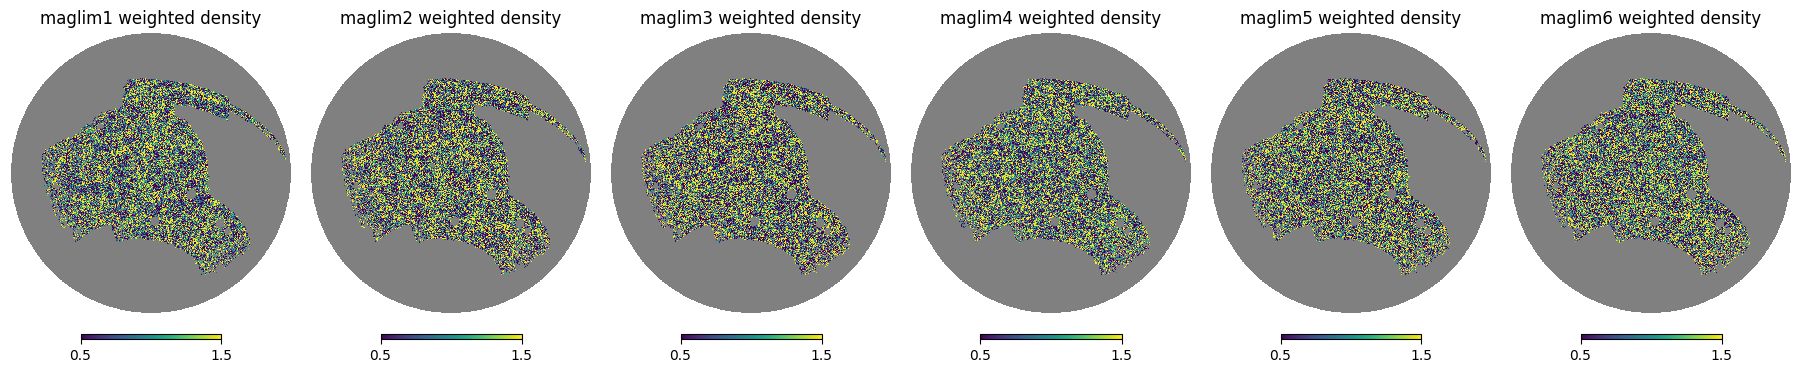

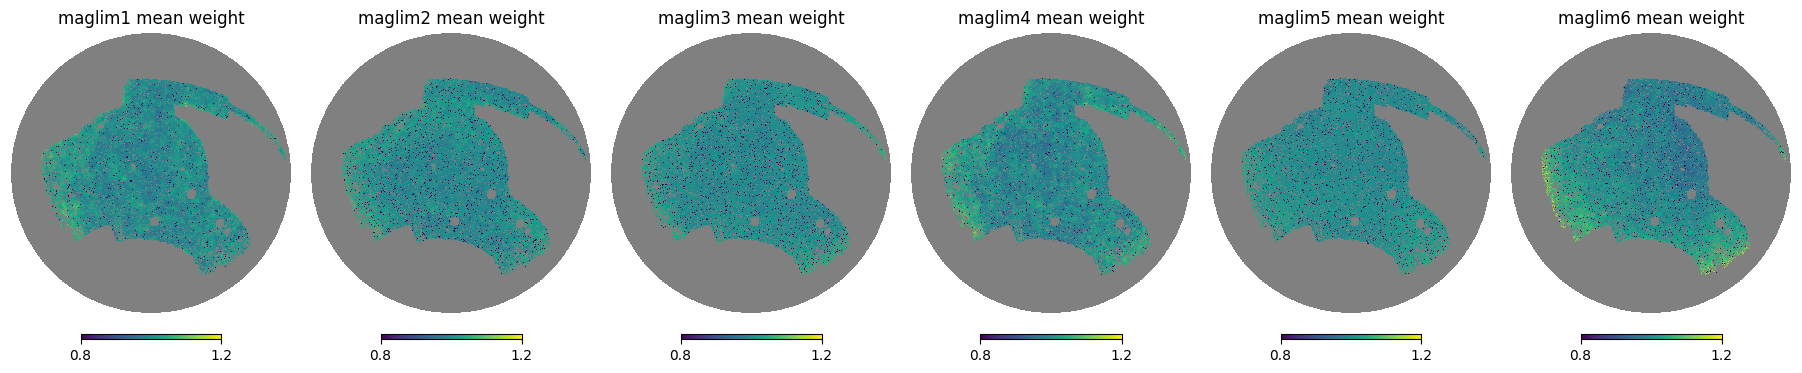

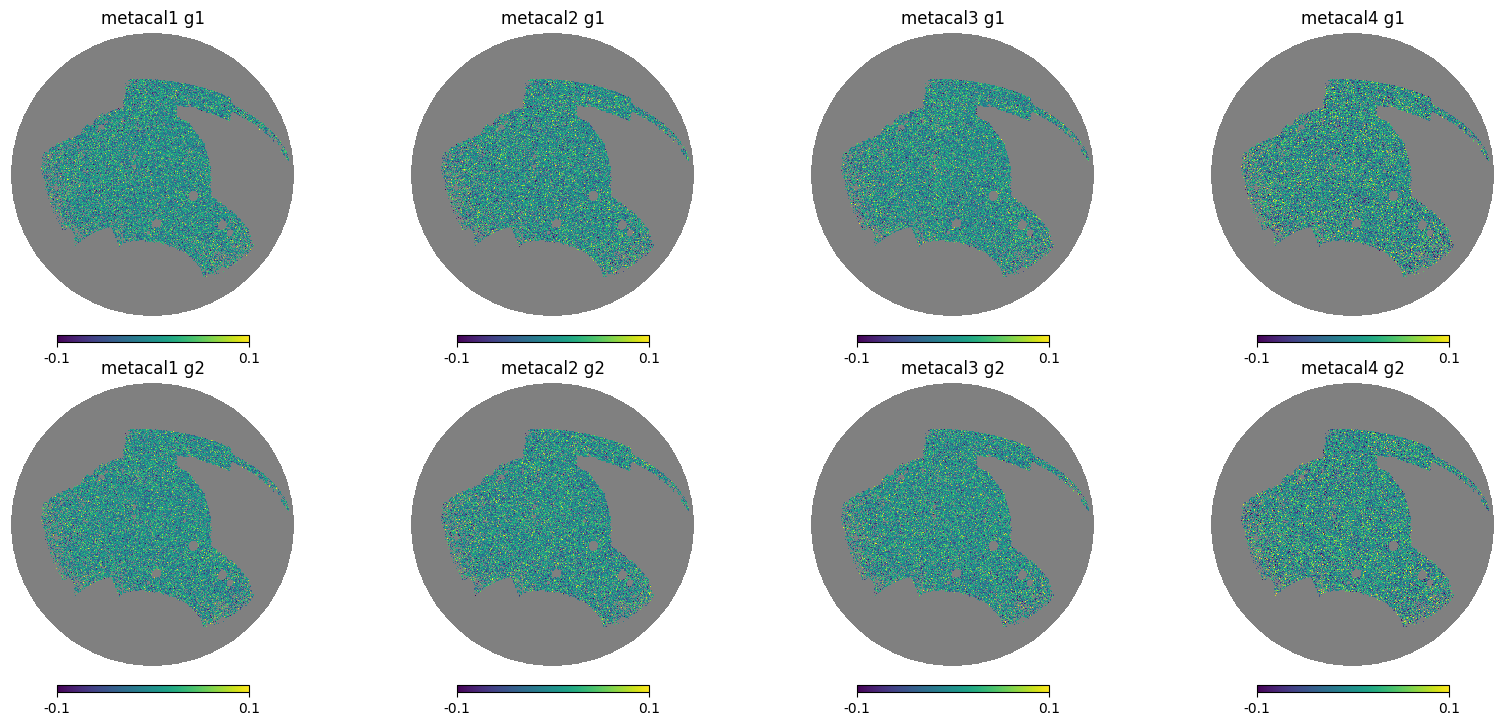

In [9]:
def show(values, title, sub, **kwargs):
    m = np.full(n_pix, hp.UNSEEN)
    m[footprint] = values[footprint]
    hp.orthview(m, rot=centre, half_sky=True, title=title, sub=sub, **kwargs)


# density relative to the footprint mean, per unit covered area
plt.figure(figsize=(16, 4))
for i, label in enumerate(survey_labels["metacal"]):
    n = source_count[:, i] / np.maximum(coverage, 1e-3)
    show(n / n[footprint].mean(), f"{label} density", (1, 4, i + 1), min=0.5, max=1.5)

plt.figure(figsize=(18, 4))
for j, label in enumerate(survey_labels["maglim"]):
    n = lens_weighted[:, j] / np.maximum(coverage, 1e-3)
    show(n / n[footprint].mean(), f"{label} weighted density", (1, 6, j + 1), min=0.5, max=1.5)

# the systematics weights: mean weight per pixel
plt.figure(figsize=(18, 4))
for j, label in enumerate(survey_labels["maglim"]):
    mean_w = lens_weighted[:, j] / np.maximum(lens_count[:, j], 1)
    show(mean_w, f"{label} mean weight", (1, 6, j + 1), min=0.8, max=1.2)

plt.figure(figsize=(16, 7))
for i, label in enumerate(survey_labels["metacal"]):
    for c in range(2):
        show(gamma[:, i, c], f"{label} g{c + 1}", (2, 4, c * 4 + i + 1), min=-0.1, max=0.1)

## MagLim weight maps

`maglim/systematics` of the pixel file. DES's fiducial lens weights come from ENet, an elastic-net regression of
each bin's density on the 19 survey-property maps (fit at nside 256, predicted at 1024); the release has them per
galaxy only. The step `pixels` turns them into w = 1/⟨F⟩ per base-patch pixel, F = 1/w being the contamination
(`catalog_desy6.maglim_weight_maps`). As in v18, w multiplies the observed counts (`apply_maglim_sys_map`) and stays
out of the forward model.

The step gates the frame (the mean galaxy weight of each pixel follows w) and the normalization (the counts times w
sum to the weighted counts). Here: the maps, and the counts against F. The raw counts should follow F with slope 1
and the corrected ones should be flat. Large-scale structure dominates the scatter, hence the jackknife errors over
nside-8 regions.

ENet weights w = 1 / <F> of maglim_2024-11-07.hdf5 on the base patch, from the per-galaxy weights (catalog_desy6.maglim_weight_maps). They multiply the observed counts. map: base-patch order; data_vector: data_vec order, 0 in the padding; filled: no galaxy in the pixel, neighbour mean 

maglim1: w in [0.922, 1.136], std 0.0230, 447 pixels filled (0.14%); sum N w / sum w_gal 0.999982
maglim2: w in [0.940, 1.103], std 0.0175, 1877 pixels filled (0.61%); sum N w / sum w_gal 0.999993
maglim3: w in [0.960, 1.092], std 0.0152, 1854 pixels filled (0.60%); sum N w / sum w_gal 1.000002
maglim4: w in [0.875, 1.137], std 0.0281, 530 pixels filled (0.17%); sum N w / sum w_gal 0.999971
maglim5: w in [0.950, 1.061], std 0.0128, 1285 pixels filled (0.42%); sum N w / sum w_gal 1.000003
maglim6: w in [0.911, 1.206], std 0.0362, 1033 pixels filled (0.33%); sum N w / sum w_gal 0.999975


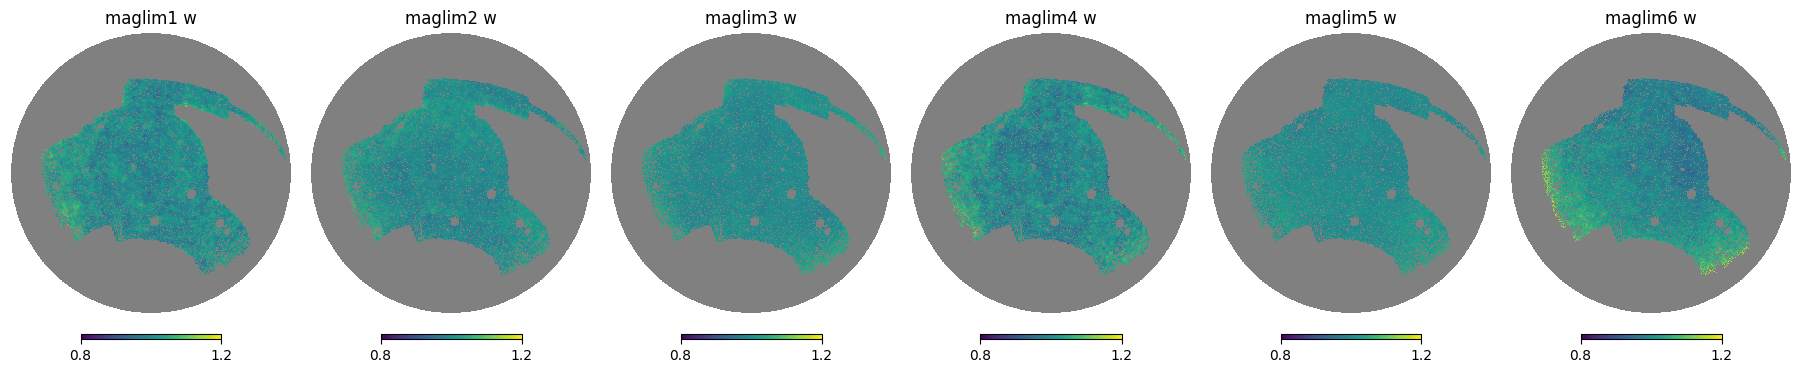

In [10]:
with h5py.File(REPO / conf["files"]["pixels"], "r") as f:
    print(f["maglim/systematics"].attrs["info"], "\n")
    lens_w, lens_w_filled = (
        np.stack([f[f"maglim/systematics/{key}/{label}"][:] for label in survey_labels["maglim"]], axis=-1)
        for key in ("map", "filled")
    )
lens_w = lens_w.astype(np.float64)

for j, label in enumerate(survey_labels["maglim"]):
    w, n, filled = lens_w[:, j], lens_count[footprint, j], lens_w_filled[:, j]
    total = np.sum(n * w) / lens_weighted[footprint, j].sum()
    print(
        f"{label}: w in [{w.min():.3f}, {w.max():.3f}], std {w.std():.4f}, {filled.sum()} pixels filled "
        f"({filled.mean():.2%}); sum N w / sum w_gal {total:.6f}"
    )

plt.figure(figsize=(18, 4))
for j, label in enumerate(survey_labels["maglim"]):
    w_map = np.zeros(n_pix)
    w_map[footprint] = lens_w[:, j]
    show(w_map, f"{label} w", (1, 6, j + 1), min=0.8, max=1.2)

In [11]:
# jackknife regions: nside-8 pixels of the rotated frame
region = hp.ring2nest(n_side, footprint) // (n_side // 8) ** 2
regions = np.unique(region)
cov_fp = coverage[footprint]


def slope(n, F, weight):
    """Slope of n / <n> against F / <F>, weighted least squares."""
    x, y = F / np.average(F, weights=weight), n / np.average(n, weights=weight)
    x_mean, y_mean = np.average(x, weights=weight), np.average(y, weights=weight)
    return np.sum(weight * (x - x_mean) * (y - y_mean)) / np.sum(weight * (x - x_mean) ** 2)


def jackknife(n, F):
    full = slope(n, F, cov_fp)
    jk = np.array([slope(n[region != r], F[region != r], cov_fp[region != r]) for r in regions])
    return full, np.sqrt((regions.size - 1) * np.mean((jk - jk.mean()) ** 2))


print(f"slope of the counts per covered area against F = 1 / w, {regions.size} jackknife regions")
print(f"{'':10s}{'raw (1)':>17s}{'corrected (0)':>19s}")
for j, label in enumerate(survey_labels["maglim"]):
    F = 1 / lens_w[:, j]
    raw = lens_count[footprint, j] / cov_fp
    (s, e), (s_corr, e_corr) = jackknife(raw, F), jackknife(raw * lens_w[:, j], F)
    print(f"{label:10s}{s:9.3f} +- {e:.3f}{s_corr:+11.3f} +- {e_corr:.3f}")

slope of the counts per covered area against F = 1 / w, 132 jackknife regions
                    raw (1)      corrected (0)


maglim1       1.220 +- 0.208     +0.211 +- 0.209


maglim2       1.115 +- 0.268     +0.109 +- 0.270


maglim3       1.374 +- 0.277     +0.375 +- 0.280


maglim4       1.019 +- 0.118     +0.017 +- 0.120


maglim5       1.147 +- 0.325     +0.157 +- 0.327


maglim6       0.908 +- 0.079     -0.095 +- 0.082


## Noise file

The shape catalog per source bin, from the first 2 million rows of each: the response-corrected ellipticities and
the weights that the `count` shape-noise model resamples.

metacal1: 33707071 galaxies (count map 33707071), weighted rms e/R = [0.27108963 0.27073164]


metacal2: 34580888 galaxies (count map 34580888), weighted rms e/R = [0.28638426 0.28611009]


metacal3: 34646416 galaxies (count map 34646416), weighted rms e/R = [0.28109893 0.28068298]


metacal4: 36727798 galaxies (count map 36727798), weighted rms e/R = [0.34208952 0.34105455]


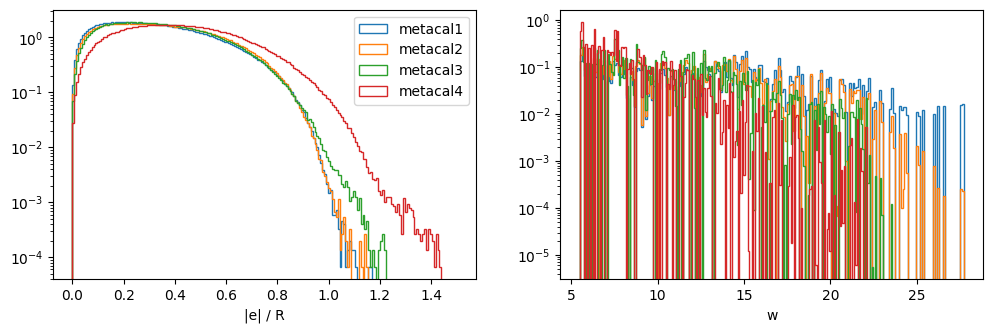

In [12]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.5))
with h5py.File(REPO / conf["files"]["noise"], "r") as f:
    for i, label in enumerate(survey_labels["metacal"]):
        cat = f[f"{label}/cat"]
        sample = cat[:2_000_000].astype(np.float64)
        e_abs, w = np.hypot(sample[:, 0], sample[:, 1]), sample[:, 2]
        rms = np.sqrt(np.average(sample[:, :2] ** 2, axis=0, weights=w))
        print(f"{label}: {cat.shape[0]} galaxies (count map {source_count[:, i].sum()}), weighted rms e/R = {rms}")
        ax0.hist(e_abs, bins=200, range=(0, 1.5), histtype="step", density=True, label=label)
        ax1.hist(w, bins=200, histtype="step", density=True, label=label)
ax0.set(xlabel="|e| / R", yscale="log")
ax1.set(xlabel="w", yscale="log")
ax0.legend()

## Shear convention: κ_E × δ_g and κ_B × δ_g

The Y3 conventions (e1 +1, e2 −1, the ψ rotation of `catalog.py`) are reused for Y6 until this test passes; for Y3
the same test validated them. κ_E and κ_B come from the footprint-masked shear maps through `lensing.mode_removal`,
as on the observation path; δ_g is the weighted MagLim count per covered area. Expected:

- κ_E × δ_g **positive** where the lens bin lies in front of the source bin. A flip of both e1 and e2 makes it
  negative; a wrong e2 parity pushes it towards zero.
- κ_B × δ_g **null**. A wrong or missing ψ rotation shows up here (−3 to −6σ per band for Y3 without it).

The E/B power alone cannot decide the overall sign. The errors are Gaussian (Knox) from the measured pseudo-spectra,
with the footprint's f_sky, so they ignore the mode coupling between neighbouring bands.

In [13]:
hp_datapath = str(REPO / conf["files"]["healpy_data"])
_, gamma2kappa_fac, _ = lensing.get_kaiser_squires_factors(3 * n_side - 1)
f_sky = in_footprint.mean()
l_max = 3 * n_side - 1
band_edges = np.array([30, 60, 100, 160, 250, 400, 630, 1000])
ell = np.arange(l_max + 1)
n_modes = np.array([np.sum(2 * ell[(ell >= lo) & (ell < hi)] + 1) for lo, hi in zip(band_edges[:-1], band_edges[1:])])


def footprint_only(m):
    """The map inside the footprint with its mean there removed, zero outside."""
    return np.where(in_footprint, m - m[in_footprint].mean(), 0.0)


def bands(cl):
    return np.array([cl[(ell >= lo) & (ell < hi)].mean() for lo, hi in zip(band_edges[:-1], band_edges[1:])])


kappa = {}
for label in used["metacal"]:
    i_survey = survey_labels["metacal"].index(label)
    g1, g2 = (np.where(in_footprint, gamma[:, i_survey, c], 0.0) for c in range(2))
    k_E, k_B = lensing.mode_removal(g1, g2, gamma2kappa_fac, n_side, hp_datapath=hp_datapath, keep_b_mode=True)
    kappa[label] = {"E": footprint_only(k_E.astype(np.float64)), "B": footprint_only(k_B.astype(np.float64))}

delta = {}
for label in used["maglim"]:
    n = lens_weighted[:, survey_labels["maglim"].index(label)]
    n_bar = n[in_footprint].sum() / coverage[in_footprint].sum()
    delta[label] = footprint_only(n / (n_bar * np.maximum(coverage, 1e-3)) - 1)

# band-averaged pseudo-spectra; the Knox error of a cross spectrum needs both autos
auto_kappa = {(label, mode): bands(hp.anafast(k[mode], lmax=l_max)) for label, k in kappa.items() for mode in "EB"}
auto_delta = {label: bands(hp.anafast(d, lmax=l_max)) for label, d in delta.items()}
cross = {}
for source, k in kappa.items():
    for lens, d in delta.items():
        for mode in "EB":
            cl = bands(hp.anafast(k[mode], d, lmax=l_max))
            sigma = np.sqrt((auto_kappa[source, mode] * auto_delta[lens] + cl**2) / (f_sky * n_modes))
            cross[source, lens, mode] = (cl, sigma)
print(f"f_sky = {f_sky:.4f}, {len(cross)} cross spectra in {len(n_modes)} bands")

f_sky = 0.0983, 40 cross spectra in 7 bands


pair                   E S/N   B S/N  B chi2/dof  lens in front
metacal1 x maglim1      15.3     2.1    7.6 / 7  yes
metacal1 x maglim3       3.3     0.8    3.7 / 7  no
metacal1 x maglim4       1.4    -0.7    6.6 / 7  no
metacal1 x maglim5       2.1     1.1    3.2 / 7  no


metacal1 x maglim6       1.4     1.7   10.3 / 7  no
metacal2 x maglim1      33.0    -0.4    7.7 / 7  yes
metacal2 x maglim3       3.9    -0.3    4.3 / 7  no
metacal2 x maglim4       2.6     0.6    4.4 / 7  no
metacal2 x maglim5       1.9    -0.1    5.4 / 7  no
metacal2 x maglim6       3.1    -0.6    4.3 / 7  no
metacal3 x maglim1      51.1    -0.3    1.9 / 7  yes
metacal3 x maglim3      20.8    -0.6    1.8 / 7  yes
metacal3 x maglim4       9.7    -0.2    2.7 / 7  yes
metacal3 x maglim5       6.3    -1.5    4.5 / 7  no
metacal3 x maglim6       4.0    -1.4    4.7 / 7  no
metacal4 x maglim1      48.1     0.4   10.0 / 7  yes
metacal4 x maglim3      31.0    -0.6    5.8 / 7  yes
metacal4 x maglim4      26.3    -0.6    2.1 / 7  yes
metacal4 x maglim5      17.6    -1.2    5.5 / 7  yes
metacal4 x maglim6      12.7    -1.0    2.6 / 7  yes


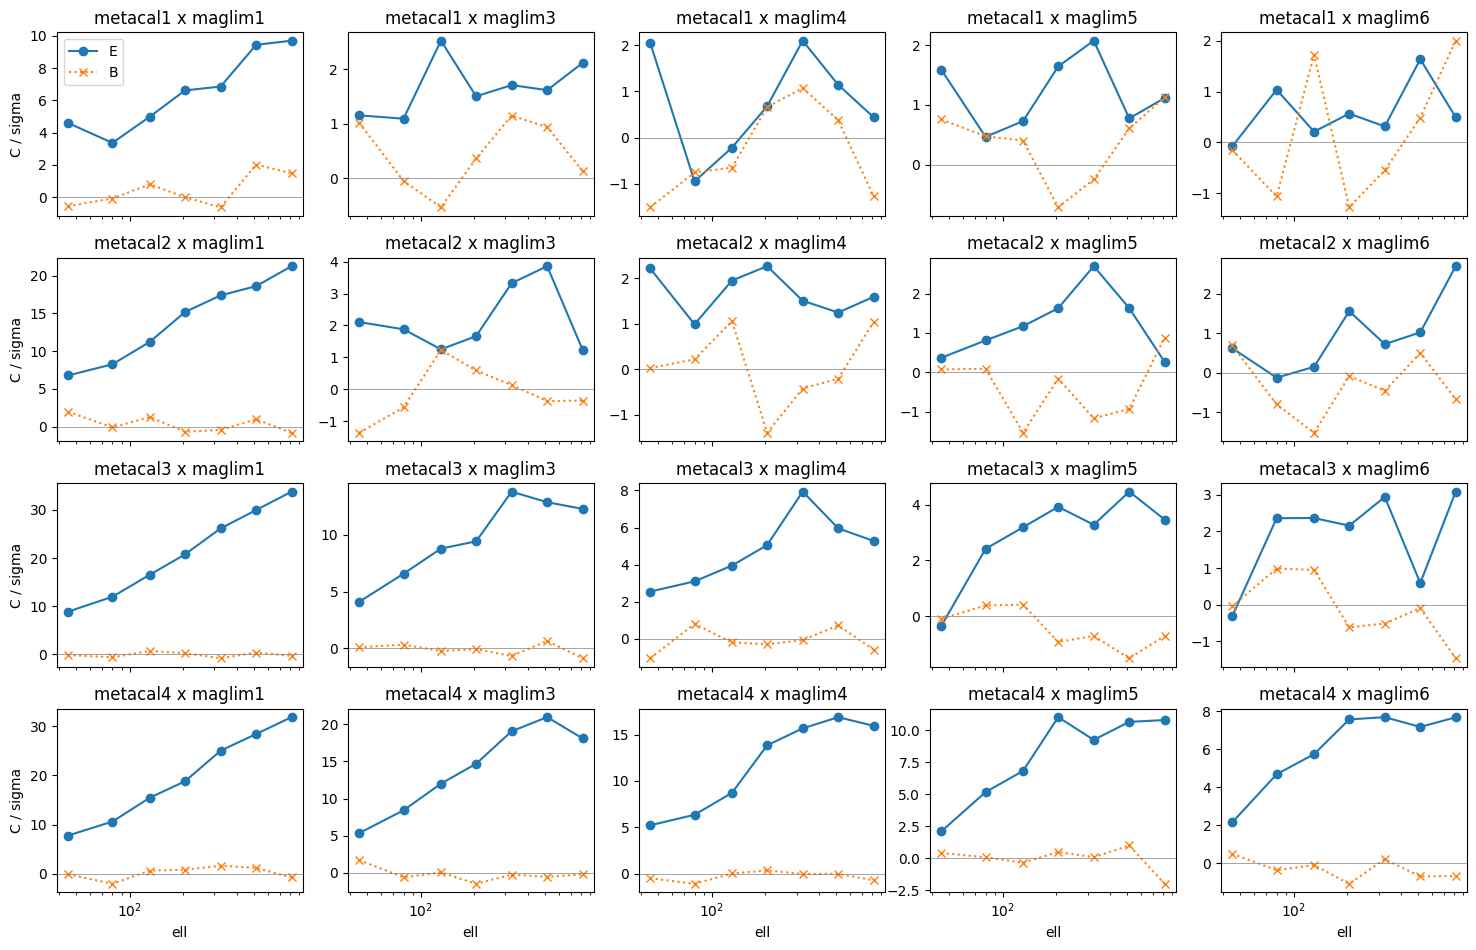

In [14]:
band_centres = 0.5 * (band_edges[:-1] + band_edges[1:])
sources, lenses = list(kappa), list(delta)


def combined(cl, sigma):
    """Inverse-variance weighted mean amplitude over the bands, in units of its error."""
    return np.sum(cl / sigma**2) / np.sqrt(np.sum(1 / sigma**2))


print(f"{'pair':20s} {'E S/N':>7s} {'B S/N':>7s} {'B chi2/dof':>11s}  lens in front")
fig, axes = plt.subplots(len(sources), len(lenses), figsize=(3 * len(lenses), 2.4 * len(sources)), sharex=True)
for r, source in enumerate(sources):
    for c, lens in enumerate(lenses):
        (cl_E, sigma_E), (cl_B, sigma_B) = cross[source, lens, "E"], cross[source, lens, "B"]
        chi2_B = np.sum((cl_B / sigma_B) ** 2)
        front = "yes" if mean_z[lens] < mean_z[source] else "no"
        print(
            f"{source + ' x ' + lens:20s} {combined(cl_E, sigma_E):7.1f} {combined(cl_B, sigma_B):7.1f} "
            f"{chi2_B:6.1f} / {len(n_modes)}  {front}"
        )

        ax = axes[r, c]
        ax.plot(band_centres, cl_E / sigma_E, "o-", label="E")
        ax.plot(band_centres, cl_B / sigma_B, "x:", label="B")
        ax.axhline(0, color="gray", lw=0.5)
        ax.set(xscale="log", title=f"{source} x {lens}")
        if c == 0:
            ax.set_ylabel("C / sigma")
        if r == len(sources) - 1:
            ax.set_xlabel("ell")
axes[0, 0].legend()
fig.tight_layout()